In [10]:
! pip install -q matplotlib numpy ISLP statsmodels

## Question 2

We will now derive the probability that a given observation is part of a bootstrap sample. Suppose that we obtain a bootstrap sample from a set of $n$ observations.

### (a)

What is the probability that the first bootstrap observation is *not* the $j$th observation from the original sample? Justify your answer.

### (b)

What is the probability that the second bootstrap observation is *not* the $j$th observation from the original sample?

### (c)

Argue that the probability that the $j$th observation is *not* in the bootstrap sample is $(1-1/n)^n$.

### (d)

When $n=5$, what is the probability that the $j$th observation is in the bootstrap sample?

### (e)

When $n=100$, what is the probability that the $j$th observation is in the bootstrap sample?

### (f)

When $n=10{,}000$, what is the probability that the $j$th observation is in the bootstrap sample?

### (g)

Create a plot that displays, for each integer value of $n$ from $1$ to $100{,}000$, the probability that the $j$th observation is in the bootstrap sample. Comment on what you observe.

### (h)

We will now investigate numerically the probability that a bootstrap sample of size $n=100$ contains the $j$th observation. Here $j=4$. We first create an array `store` with values that will subsequently be overwritten using the function `np.empty()`. We then repeatedly create bootstrap samples, and each time we record whether or not the fifth observation is contained in the bootstrap sample.

```python
rng = np.random.default_rng(10)
store = np.empty(10000)
for i in range(10000):
    store[i] = np.sum(rng.choice(100, replace=True) == 4) > 0
np.mean(store)
```

Comment on the results obtained.


### (a) 解答

第一次抽樣時，每一筆原始資料被抽到的機率都是 $1/n$，因此抽到第 $j$ 筆資料的機率為

$$
P(\text{第一次抽到第 }j\text{ 筆})
=
\frac{1}{n}.
$$

所以第一次沒有抽到第 $j$ 筆資料的機率為

$$
\boxed{
P(\text{第一次未抽到第 }j\text{ 筆})
=
1-\frac{1}{n}.
}
$$

### (b) 解答

由於 bootstrap 採用有放回抽樣，所以本質上應該要與 (a) 小題一樣。

第一次抽樣後，第二次仍然從完整的 $n$ 筆原始資料中抽取。

所以，

$$
\boxed{
P(\text{第二次未抽到第 }j\text{ 筆})
=
1-\frac{1}{n}.
}
$$


### (c) 解答

一個 bootstrap 樣本由 $n$ 次有放回抽樣組成，所以理論上 $n$ 次抽樣彼此獨立。

而每次未抽到第 $j$ 筆資料的機率都是 $1-1/n$，因此

$$
\begin{aligned}
P(\text{第 }j\text{ 筆完全未出現})
&=
\prod_{r=1}^{n}
P(\text{第 }r\text{ 次未抽到第 }j\text{ 筆})\\
&=
\prod_{r=1}^{n}\left(1-\frac{1}{n}\right)\\
&=
\boxed{\left(1-\frac{1}{n}\right)^n}.
\end{aligned}
$$

因此，第 $j$ 筆資料至少出現一次的機率為

$$
\boxed{
P(\text{第 }j\text{ 筆至少出現一次})
=
1-\left(1-\frac{1}{n}\right)^n.
}
$$

### (d) 解答

將 $n=5$ 代入公式：

$$
\begin{aligned}
P(\text{第 }j\text{ 筆至少出現一次})
&=
1-\left(1-\frac{1}{5}\right)^5\\
&=
1-\left(\frac45\right)^5\\
&=
\boxed{0.67232}.
\end{aligned}
$$

因此，機率約為 **67.23%**。

In [11]:
n = 5
probability_d = 1 - (1 - 1 / n) ** n

print(f"n = {n}")
print(f"至少出現一次的機率：{probability_d:.8f}")

n = 5
至少出現一次的機率：0.67232000


### (e) 解答

將 $n=100$ 代入公式：

$$
\begin{aligned}
P(\text{第 }j\text{ 筆至少出現一次})
&=
1-\left(1-\frac{1}{100}\right)^{100}\\
&=
1-(0.99)^{100}\\
&\approx
\boxed{0.63396766}.
\end{aligned}
$$

因此，機率約為 **63.40%**。

In [12]:
n = 100

probability_e = 1 - (1 - 1 / n) ** n

print(f"n = {n}")
print(f"至少出現一次的機率：{probability_e:.8f}")

n = 100
至少出現一次的機率：0.63396766


### (f) 解答

將 $n=10{,}000$ 代入公式：

$$
\begin{aligned}
P(\text{第 }j\text{ 筆至少出現一次})
&=
1-\left(1-\frac{1}{10{,}000}\right)^{10{,}000}\\
&=
1-(0.9999)^{10{,}000}\\
&\approx
\boxed{0.63213895}.
\end{aligned}
$$

因此，機率約為 **63.21%**。

In [13]:
n = 10000
probability_f = 1 - (1 - 1 / n) ** n

print(f"n = {n:,}")
print(f"至少出現一次的機率：{probability_f:.8f}")

n = 10,000
至少出現一次的機率：0.63213895


### (g) 解答

對每個整數 $n=1,2,\ldots,100{,}000$，計算

$$
p_n
=
1-\left(1-\frac{1}{n}\right)^n,
$$

並繪製 $n$ 與 $p_n$ 的關係圖。

當 $n=1$ 時，原始資料只有一筆，因此唯一的觀測值一定會被抽到：

$$
p_1=1.
$$

隨著 $n$ 增加，納入機率逐漸降低，並趨近固定值。因為根據 $e$ 的極限公式可知

$$
\lim_{n\to\infty}
\left(1-\frac{1}{n}\right)^n
=
e^{-1},
$$

所以

$$
\boxed{
\lim_{n\to\infty}p_n
=
1-e^{-1}
\approx 0.63212056.
}
$$

因此，當 $n$ 很大時，某一筆指定資料至少出現一次的機率約為 **63.21%**，完全沒有出現的機率則約為 **36.79%**。

底下的圖也可以說明曲線機率是會收斂到定值，造成這個不太值觀結果我猜是因為因為抽樣允許重複，即使 bootstrap 樣本抽了 $n$ 筆，也不代表原始的每一筆資料都會出現。

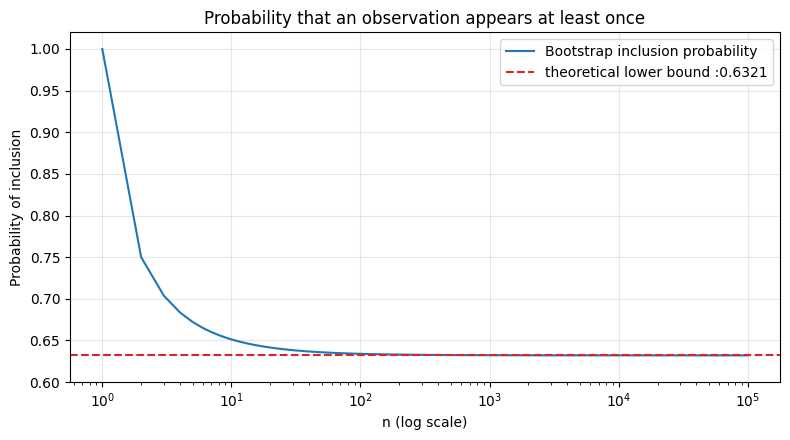

n = 1 時的機率：1.00000000
n = 100,000 時的機率：0.63212240
理論極限：0.63212056


In [14]:
import numpy as np
import matplotlib.pyplot as plt

# 包含 1 到 100,000 的每一個整數
n_values = np.arange(1, 100001)

# 各樣本大小對應的納入機率
probabilities = 1 - (1 - 1 / n_values) ** n_values

# 理論極限
limit = 1 - np.exp(-1)

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.semilogx(
    n_values,
    probabilities,
    label="Bootstrap inclusion probability",
)

ax.axhline(
    limit,
    color="tab:red",
    linestyle="--",
    label=f"theoretical lower bound :{limit:.4f}",
)

ax.set(
    xlabel="n (log scale)",
    ylabel="Probability of inclusion",
    title="Probability that an observation appears at least once",
    ylim=(0.60, 1.02),
)

ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

print(f"n = 1 時的機率：{probabilities[0]:.8f}")
print(f"n = 100,000 時的機率：{probabilities[-1]:.8f}")
print(f"理論極限：{limit:.8f}")

### (h) 解答

設定原始資料共有 $n=100$ 筆，並重複產生 10,000 個 bootstrap 樣本。

每個 bootstrap 樣本都從原始的 100 筆資料中，有放回地抽取 100 次。

題目程式使用索引 `4`。由於 Python 的索引從 0 開始，因此這代表原始資料中的第 5 筆觀測值。

對每一次模擬，記錄這筆資料是否至少出現一次：

$$
I_b
=
\begin{cases}
1, & \text{指定觀測值在第 }b\text{ 個 bootstrap 樣本中至少出現一次},\\
0, & \text{指定觀測值完全沒有出現}.
\end{cases}
$$

令模擬次數為 $B=10{,}000$，則納入機率的模擬估計值為

$$
\hat p
=
\frac{1}{B}\sum_{b=1}^{B}I_b.
$$

使用亂數種子 10，在本次執行中，指定觀測值出現在 6,362 個 bootstrap 樣本中，因此

$$
\hat p
=
\frac{6362}{10000}
=
\boxed{0.6362}.
$$

理論機率則為

$$
p
=
1-\left(1-\frac{1}{100}\right)^{100}
\approx \boxed{0.63396766}.
$$

模擬結果約為 **63.62%**，跟理論值 **63.40%**差不多。兩者的些微差異來自有限模擬次數所產生的隨機誤差。

In [15]:
rng = np.random.default_rng(10)

n = 100
B = 10000
target_index = 4  

# 每個元素記錄一次模擬中，指定觀測值是否至少出現一次
store = np.empty(B, dtype=bool)

for i in range(B):
    # 從索引 0～99 中，有放回地抽取 100 次
    bootstrap_indices = rng.choice(
        n,
        size=n,
        replace=True,
    )
    store[i] = np.any(bootstrap_indices == target_index)

# True、False 取平均，等同於 1、0 取平均
estimated_probability = store.mean()

# 理論機率
theoretical_probability = 1 - (1 - 1 / n) ** n

print(f"模擬次數：{B:,}")
print(f"模擬機率：{estimated_probability:.6f}")
print(f"理論機率：{theoretical_probability:.6f}")
print(
    "兩者的絕對差異："
    f"{abs(estimated_probability - theoretical_probability):.6f}"
)

模擬次數：10,000
模擬機率：0.636200
理論機率：0.633968
兩者的絕對差異：0.002232


## Question 3

We now review $k$-fold cross-validation.

### (a)

Explain how $k$-fold cross-validation is implemented.

### (b)

What are the advantages and disadvantages of $k$-fold cross-validation relative to:

i. The validation set approach?

ii. LOOCV?


### (a) 解釋

$k$ 折交叉驗證的目的是利用現有資料，估計模型對新資料的預測誤差。

假設共有 $n$ 筆觀測資料：

1. 將資料隨機分成 $k$ 組大小相同或接近、彼此不重疊的資料，每一組稱為一個 fold。
2. 第一次以第 1 組作為驗證集，其餘 $k-1$ 組作為訓練集。
3. 使用訓練集建立模型，再計算模型在驗證集上的預測誤差。
4. 依序讓第 2 組、第 3 組，直到第 $k$ 組作為驗證集；每次都使用其餘資料重新訓練模型。
5. 將這 $k$ 次的驗證誤差取平均，作為模型測試誤差的估計值。

因此，整個過程通常需要訓練模型 $k$ 次，每筆觀測資料都會作為驗證資料一次、訓練資料 $k-1$ 次。

若各組大小相同，令 $\mathrm{Err}_j$ 表示第 $j$ 組的平均驗證誤差，則

$$
\mathrm{CV}_{(k)}
=
\frac{1}{k}\sum_{j=1}^{k}\mathrm{Err}_j.
$$

在迴歸問題中，可以使用均方誤差：

$$
\mathrm{CV}_{(k)}
=
\frac{1}{k}\sum_{j=1}^{k}\mathrm{MSE}_j.
$$

在分類問題中，則可以將各組的分類錯誤率取平均。

如果各組大小不完全相同，令 $n_j$ 為第 $j$ 組的觀測筆數，可以使用加權平均，使每筆驗證資料具有相同的權重：

$$
\mathrm{CV}_{(k)}
=
\sum_{j=1}^{k}\frac{n_j}{n}\mathrm{Err}_j.
$$

例如，將 100 筆資料進行 5 折交叉驗證，每組包含 20 筆資料。每次使用 80 筆資料訓練、20 筆資料驗證，共進行 5 次，最後將 5 次驗證誤差取平均。

特別要注意的是一定要避免資料洩漏問題

### (b) 解釋

#### i. 與 validation set approach 比較

Validation set approach 只將資料切分一次，使用其中一部分訓練模型，再使用剩下的資料計算驗證誤差。

$k-fold$ 優點：

1. **較不依賴單次資料切分**

   單次驗證集方法的結果，可能受到哪些資料被分入訓練集或驗證集的明顯影響。

   $k$ 折交叉驗證讓每筆資料都作為驗證資料一次，並平均多次驗證結果，因此通常能得到較穩定的誤差估計。

2. **在常見切分比例下，每次可以使用較多資料訓練**

   $k$ 折交叉驗證每次使用的訓練資料比例約為

   $$
   \frac{k-1}{k}.
   $$

   例如，5 折使用 80% 的資料訓練，10 折使用 90% 的資料訓練。

   如果單次驗證集方法只使用 50% 或 70% 的資料訓練，交叉驗證每次就能使用較多的訓練資料。由於使用較少資料訓練的模型通常表現較差，單次驗證集方法可能較容易高估使用全部訓練資料所建立之模型的測試誤差。

$k-fold$ 缺點：

1. **計算成本較高**

   單次驗證集方法只需要訓練模型一次，而 $k$ 折交叉驗證通常需要訓練模型 $k$ 次。

2. **仍然受到隨機分組影響**

   雖然平均多次驗證結果通常能提高穩定性，但將資料分成不同的 folds，仍可能得到不同的交叉驗證誤差。

#### ii. 與 LOOCV 比較

LOOCV 是 $k=n$ 的特殊情況，其中 $n$ 為資料筆數。

每次只保留一筆資料作為驗證資料，其餘 $n-1$ 筆資料用來訓練模型，輪流驗證全部 $n$ 筆資料後，再將誤差取平均。

$k-fold$ 優點：

1. **計算成本通常較低**

   一般的 $k$ 折交叉驗證需要訓練模型 $k$ 次，而直接執行 LOOCV 需要訓練模型 $n$ 次。

   當 $k$ 遠小於 $n$ 時，例如資料很多但只使用 5 折或 10 折，$k$ 折交叉驗證通常可以節省大量計算時間。

2. **測試誤差估計值通常具有較低的變異數**

   LOOCV 各次使用的訓練集高度重疊，因此得到的模型非常相似，各次誤差之間可能具有較強的相關性。對高度相關的誤差取平均，降低變異的效果有限。

   使用 5 折或 10 折時，各次訓練集的差異較大，因此測試誤差估計值往往比 LOOCV 更穩定。不過，這是常見的表現，並非對所有模型與資料都必然成立。

$k-fold$ 缺點：

1. **通常具有較大的悲觀偏誤**

   $k$ 折交叉驗證每次使用的訓練資料筆數約為

   $$
   \frac{k-1}{k}n,
   $$

   而 LOOCV 每次使用 $n-1$ 筆資料。

   當 $k<n$ 時，$k$ 折交叉驗證每次使用的訓練資料較少，因此模型表現通常較差，估計出的測試誤差也可能較高。

   LOOCV 的訓練資料量更接近完整的 $n$ 筆資料，因此在估計完整資料模型的測試誤差時，通常具有較小的偏誤。

2. **受到隨機分組影響**

   $k$ 折交叉驗證的結果可能隨 folds 的分法而改變。

   LOOCV 則固定為每次留下一筆資料，因此對同一份資料而言，沒有隨機分組造成的差異。

## Question 6

We continue to consider the use of a logistic regression model to predict the probability of `default` using `income` and `balance` on the `Default` data set. In particular, we will now compute estimates for the standard errors of the `income` and `balance` logistic regression coefficients in two different ways: (1) using the bootstrap, and (2) using the standard formula for computing the standard errors in the `sm.GLM()` function. Do not forget to set a random seed before beginning your analysis.

### (a)

Using the `summarize()` and `sm.GLM()` functions, determine the estimated standard errors for the coefficients associated with `income` and `balance` in a multiple logistic regression model that uses both predictors.

### (b)

Write a function, `boot_fn()`, that takes as input the `Default` data set as well as an index of the observations, and that outputs the coefficient estimates for `income` and `balance` in the multiple logistic regression model.

### (c)

Following the bootstrap example in the lab, use your `boot_fn()` function to estimate the standard errors of the logistic regression coefficients for `income` and `balance`.

### (d)

Comment on the estimated standard errors obtained using the `sm.GLM()` function and using the bootstrap.


### (a) 解釋

將 `default = "Yes"` 設為 1，`default = "No"` 設為 0，並使用 `income` 和 `balance` 建立多元 logistic regression 模型：

$$
\log\left(
\frac{P(\mathrm{default}=\mathrm{Yes}\mid \mathrm{income},\mathrm{balance})}
{1-P(\mathrm{default}=\mathrm{Yes}\mid \mathrm{income},\mathrm{balance})}
\right)
=
\beta_0
+
\beta_{\mathrm{income}}\mathrm{income}
+
\beta_{\mathrm{balance}}\mathrm{balance}.
$$

用 `sm.GLM()` 配適二項分布、logit 連結函數的模型，接著使用 `summarize()` 整理估計結果。

兩個預測變數的係數估計值與標準誤如下：

| 變數 | 係數估計值 | 標準誤 |
|---|---:|---:|
| `income` | $2.08090\times 10^{-5}$ | $4.98525\times 10^{-6}$ |
| `balance` | $5.64710\times 10^{-3}$ | $2.27381\times 10^{-4}$ |

因此，題目要求的標準誤為

$$
\widehat{\operatorname{SE}}
\left(\hat{\beta}_{\mathrm{income}}\right)
\approx 4.98525\times 10^{-6},
$$

$$
\widehat{\operatorname{SE}}
\left(\hat{\beta}_{\mathrm{balance}}\right)
\approx 2.27381\times 10^{-4}.
$$

這些標準誤描述的是迴歸係數估計值的抽樣變動程度。
這兩個標準誤表示：如果重新抽取相同筆數的資料，並重新建立相同的 logistic regression 模型，兩個係數的估計值會有多大的變動。

**1. income 標準誤與係數大小比較**

$$
\frac{
\widehat{\operatorname{SE}}(\hat{\beta}_{\mathrm{income}})
}{
|\hat{\beta}_{\mathrm{income}}|
}
=
\frac{4.98525\times 10^{-6}}
{2.08090\times 10^{-5}}
\approx 23.96\%.
$$

因此，`income` 的標準誤約為其係數估計值大小的 23.96%，反映出一定程度的估計不確定性。

**2. balance 標準誤與係數大小比較**

$$
\frac{
\widehat{\operatorname{SE}}(\hat{\beta}_{\mathrm{balance}})
}{
|\hat{\beta}_{\mathrm{balance}}|
}
=
\frac{2.27381\times 10^{-4}}
{5.64710\times 10^{-3}}
\approx 4.03\%.
$$

因此，`balance` 的標準誤約為其係數估計值大小的 4.03%。相對於各自的係數大小，`balance` 的估計比 `income` 更精確，因為係數與標準誤都有帶單位，所以用比例可以消除單位造成的影響。

另外，上述百分比描述的是「標準誤相對於係數大小的比例」，並不是違約預測的錯誤率，也不代表係數與真實值相差這個百分比。

In [16]:
import statsmodels.api as sm

from ISLP import load_data
from ISLP.models import summarize

seed = 20261019
rng = np.random.default_rng(seed)

# 載入資料
Default = load_data("Default")

predictors = ["income", "balance"]

# Yes = 1：違約；No = 0：未違約
y = (Default["default"] == "Yes").astype(int)

# 加入截距項
X = sm.add_constant(
    Default[predictors],
    has_constant="add",
)

# Binomial 預設使用 logit 連結函數
glm_result = sm.GLM(
    y,
    X,
    family=sm.families.Binomial(),
).fit()

glm_summary = summarize(glm_result)

# 以原始數值取代摘要表中已四捨五入的係數與標準誤
glm_summary["coef"] = glm_result.params
glm_summary["std err"] = glm_result.bse

print("迴歸係數與 GLM 標準誤：")
print(
    glm_summary.loc[predictors, ["coef", "std err"]].to_string(
        float_format=lambda value: f"{value:.8e}"
    )
)

# 保留標準誤給 d 
glm_se = glm_result.bse.loc[predictors]

迴歸係數與 GLM 標準誤：
                  coef        std err
income  2.08089755e-05 4.98524546e-06
balance 5.64710295e-03 2.27381384e-04


### (b) 解答

定義 `boot_fn(data, index)`，其中：

- `data` 是原始的 `Default` 資料集。
- `index` 是要抽取的資料列位置，可以包含重複的位置。

函數首先根據 `index` 取出資料，再使用抽出的資料配適包含截距、`income` 與 `balance` 的 logistic regression 模型，最後回傳

$$
\hat{\beta}_{\mathrm{income}}
\quad\text{與}\quad
\hat{\beta}_{\mathrm{balance}}.
$$

由於 bootstrap 採用有放回抽樣，同一筆觀測資料可能被抽中多次，因此必須保留重複抽中的資料列。

本函數使用 `iloc[index]` 依資料列位置取樣，能保留這些重複觀測。

In [20]:
def boot_fn(data, index):
    # 根據位置取樣，保留重複抽中的資料列
    sample = data.iloc[index]

    y_boot = (sample["default"] == "Yes").astype(int)

    X_boot = sm.add_constant(
        sample[["income", "balance"]],
        has_constant="add",
    )

    result = sm.GLM(
        y_boot,
        X_boot,
        family=sm.families.Binomial(),
    ).fit()

    if not result.converged:
        raise RuntimeError("此次抽樣的 logistic regression 未收斂。")

    return result.params.loc[["income", "balance"]]

### (c) 解答

設原始資料共有 $n$ 筆觀測資料，執行 $B=1000$ 次 bootstrap。

每一次重抽樣的步驟如下：

1. 從原始資料的 $n$ 筆觀測中，有放回地抽取 $n$ 筆資料。
2. 使用 `boot_fn()` 對這份 bootstrap 樣本重新配適 logistic regression。
3. 記錄 `income` 與 `balance` 的係數估計值。

抽樣時以整筆觀測資料為單位，因此每筆資料中的 `default`、`income` 與 `balance` 會一起被抽出。

令 $\hat{\beta}_{j}^{*(b)}$ 表示第 $b$ 次 bootstrap 得到的第 $j$ 個係數估計值，其中 $j$ 分別代表 `income` 或 `balance`。

首先計算 bootstrap 係數的平均值：

$$
\overline{\hat{\beta}_{j}^{*}}
=
\frac{1}{B}
\sum_{b=1}^{B}
\hat{\beta}_{j}^{*(b)}.
$$

再以這 $B$ 個係數估計值的樣本標準差，估計原始係數估計值的標準誤：

$$
\widehat{\operatorname{SE}}_{\mathrm{boot}}
\left(\hat{\beta}_{j}\right)
=
\sqrt{
\frac{1}{B-1}
\sum_{b=1}^{B}
\left(
\hat{\beta}_{j}^{*(b)}
-
\overline{\hat{\beta}_{j}^{*}}
\right)^2
}.
$$

使用亂數種子 1，重複抽樣 1,000 次，得到：

| 變數 | Bootstrap 標準誤 |
|---|---:|
| `income` | $4.82\times 10^{-6}$ |
| `balance` | $2.25\times 10^{-4}$ |

相較於 `sm.GLM()` 計算出的標準誤（`income`：$4.98525\times10^{-6}$；`balance`：$2.27381\times10^{-4}$），bootstrap 的標準誤分別僅低約 **2.24%** 與 **0.65%**，差異不大，所以兩種方法對係數不確定性的估計相近，模型公式所估計的標準誤與重抽樣觀察到的係數變動程度大致一致。

In [19]:
import pandas as pd

B = 1000
n = len(Default)

# 在抽樣開始前重設一次，方便重新執行本儲存格時重現結果
rng = np.random.default_rng(seed)

# 每列記錄一次 bootstrap 的兩個係數
bootstrap_values = np.empty((B, len(predictors)))

for b in range(B):
    # 有放回抽取 n 個資料列位置
    index = rng.choice(
        n,
        size=n,
        replace=True,
    )

    # 使用 (b) 的函數重新估計係數
    bootstrap_values[b] = boot_fn(
        Default,
        index,
    ).to_numpy()

bootstrap_coefs = pd.DataFrame(
    bootstrap_values,
    columns=predictors,
)

# Bootstrap 標準誤：各係數在不同重抽樣之間的樣本標準差
bootstrap_se = bootstrap_coefs.std(ddof=1)

print(f"Bootstrap 次數：{B}")
print("Bootstrap 標準誤：")
print(
    bootstrap_se.to_string(
        float_format=lambda value: f"{value:.8e}"
    )
)

Bootstrap 次數：1000
Bootstrap 標準誤：
income    4.81912512e-06
balance   2.24843930e-04


### (d) 解答

兩種方法得到的結果如下：

| 變數 | GLM 標準誤 | Bootstrap 標準誤 |
|---|---:|---:|
| `income` | $4.98525\times10^{-6}$ | $4.82\times10^{-6}$ |
| `balance` | $2.27381\times10^{-4}$ | $2.25\times10^{-4}$ |

以 GLM 的標準誤為基準，`income` 的 bootstrap 標準誤約低 **2.24%**，`balance` 則約低 **0.65%**，兩者的差異都不大，尤其 `balance` 的結果非常接近。

GLM 利用模型的大樣本近似公式計算標準誤，而 bootstrap 透過反覆重抽資料、重新估計係數，以係數的變動程度估計標準誤。雖然計算方式不同，兩種方法仍得到相近的結果，表示本次分析中，模型公式所估計的係數不確定性與重抽樣觀察到的變動程度大致一致。

## Question 8

We will now perform cross-validation on a simulated data set.

### (a)

Generate a simulated data set as follows:

```python
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
```

In this data set, what is $n$ and what is $p$? Write out the model used to generate the data in equation form.

### (b)

Create a scatterplot of $X$ against $Y$. Comment on what you find.

### (c)

Set a random seed, and then compute the LOOCV errors that result from fitting the following four models using least squares:

i. $Y = \beta_0 + \beta_1 X + \epsilon$

ii. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \epsilon$

iii. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \epsilon$

iv. $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \beta_4 X^4 + \epsilon$.

Note you may find it helpful to use the `data.frame()` function to create a single data set containing both $X$ and $Y$.

### (d)

Repeat (c) using another random seed, and report your results. Are your results the same as what you got in (c)? Why?

### (e)

Which of the models in (c) had the smallest LOOCV error? Is this what you expected? Explain your answer.

### (f)

Comment on the statistical significance of the coefficient estimates that results from fitting each of the models in (c) using least squares. Do these results agree with the conclusions drawn based on the cross-validation results?


### (a) 解釋


根據題目指定的程式，先產生 100 個服從標準常態分布的 $X$，再以 $X-2X^2$ 加上隨機誤差，產生對應的 $Y$。

因此，資料生成模型為

$$
Y_i=X_i-2X_i^2+\epsilon_i,
\qquad i=1,\ldots,100,
$$

其中

$$
X_i\overset{\mathrm{iid}}{\sim}N(0,1),
\qquad
\epsilon_i\overset{\mathrm{iid}}{\sim}N(0,1),
$$

且誤差與輸入變數彼此獨立。

資料共包含 100 組 $(X_i,Y_i)$，所以樣本數為

$$
\boxed{n=100}.
$$

以資料的原始預測變數數目定義 $p$，由於只有一個預測變數 $X$，因此

$$
\boxed{p=1}.
$$

雖然生成模型包含 $X$ 和 $X^2$ 兩個解釋項，但 $X^2$ 是由原始變數 $X$ 平方得到的轉換項。因此，應區分「一個原始預測變數」與「二次模型中的兩個非截距解釋項」。

將生成模型寫成一般二次迴歸形式：

$$
Y_i
=
\beta_0+\beta_1X_i+\beta_2X_i^2+\epsilon_i,
$$

其真實係數為

$$
\beta_0=0,\qquad
\beta_1=1,\qquad
\beta_2=-2.
$$

由於誤差與 $X$ 獨立且平均數為 0，$Y$ 的條件平均數為

$$
E(Y\mid X=x)=x-2x^2.
$$

這表示 $X$ 與 $Y$ 的平均關係是一條開口向下的拋物線，而隨機誤差使實際觀測值分散在這條曲線周圍。

In [ ]:
# 使用亂數種子產生資料
rng = np.random.default_rng(1)

x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)

# 儲存原始模擬資料
data = pd.DataFrame({
    "x": x,
    "y": y,
})

# 二次模型的兩個非截距解釋項
X_quadratic = pd.DataFrame({
    "x": x,
    "x_squared": x**2,
})

print(f"樣本數 n：{len(data)}")
print("原始輸入變數數目：1（x）")
print(f"二次模型的解釋項數目 p：{X_quadratic.shape[1]}（x、x²）")

print("前五筆資料：")
print(data.head())

樣本數 n：100
原始輸入變數數目：1（x）
二次模型的解釋項數目 p：2（x、x²）
前五筆資料：
          x         y
0  0.345584 -0.544554
1  0.821618  0.333950
2  0.330437 -0.013532
3 -1.303157 -4.030442
4  0.905356  0.484861


### (b) 解答

以 $X$ 為橫軸、$Y$ 為縱軸繪製散佈圖，可以看到資料呈現明顯的倒 U 型分布，表示兩者有非線性的關係。

在 $X$ 較小的區域，$Y$ 整體隨著 $X$ 增加而上升；通過曲線頂點附近後，$Y$ 則隨著 $X$ 增加而下降。

這與資料生成模型的條件平均數

$$
E(Y\mid X=x)=x-2x^2
$$

一致。由於二次項係數為 $-2$，曲線開口向下，且理論上的頂點位於 $x=0.25$。

觀測點沒有完全落在拋物線上，是因為生成 $Y$ 時加入了隨機誤差 $\epsilon$，使資料散布在平均曲線周圍。

因此，從圖形判斷，包含 $X^2$ 的二次模型應比單純的直線模型更能描述資料的主要趨勢。

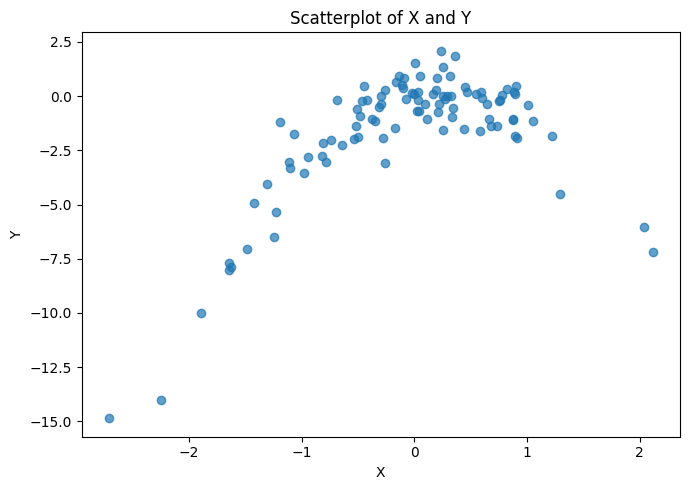

In [24]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(x, y, alpha=0.7)

ax.set(
    xlabel="X",
    ylabel="Y",
    title="Scatterplot of X and Y",
)

fig.tight_layout()
plt.show()

### (c) 解答

使用 (a) 產生的同一份資料，以最小平方法分別配適下列四個模型：

$$
\begin{aligned}
\text{(i)}\quad
Y &= \beta_0+\beta_1X+\epsilon,\\
\text{(ii)}\quad
Y &= \beta_0+\beta_1X+\beta_2X^2+\epsilon,\\
\text{(iii)}\quad
Y &= \beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon,\\
\text{(iv)}\quad
Y &= \beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\beta_4X^4+\epsilon.
\end{aligned}
$$

對每個模型進行留一交叉驗證：每次保留第 $i$ 筆資料作為驗證資料，使用其餘 99 筆資料重新估計模型，再預測被保留的觀測值。

令 $\hat{Y}_i^{(-i)}$ 表示「未使用第 $i$ 筆資料訓練的模型」對該筆資料所做的預測，則 LOOCV 均方誤差為

$$
\mathrm{CV}_{(100)}
=
\frac{1}{100}
\sum_{i=1}^{100}
\left(Y_i-\hat{Y}_i^{(-i)}\right)^2.
$$

計算結果如下：

| 模型 | 多項式次數 | LOOCV 均方誤差 |
|---|---:|---:|
| (i) 一次模型 | 1 | 6.633030 |
| (ii) 二次模型 | 2 | 1.122937 |
| (iii) 三次模型 | 3 | 1.301797 |
| (iv) 四次模型 | 4 | 1.332394 |

加入二次項後，LOOCV 誤差由 6.633030 大幅下降至 1.122937，表示二次項能有效描述資料中的彎曲關係，改善對未參與訓練之觀測值的預測。

進一步加入三次與四次項後，LOOCV 誤差反而略為上升，顯示在這份資料中，增加這些高次項並沒有帶來更好的預測表現。

因此，本次四個模型中，以二次模型的 LOOCV 誤差最低。

In [25]:
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

np.random.seed(1)

# sklearn 的預測變數需要是二維陣列
X = x.reshape(-1, 1)

loo = LeaveOneOut()
results = []

for degree in range(1, 5):
    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False,
        ),
        LinearRegression(fit_intercept=True),
    )

    # 每次使用 99 筆資料訓練，1 筆資料驗證
    scores = cross_val_score(
        model,
        X,
        y,
        cv=loo,
        scoring="neg_mean_squared_error",
    )

    # sklearn 回傳負的 MSE，取負號還原為正的誤差
    loocv_mse = -scores.mean()

    results.append({
        "degree": degree,
        "LOOCV_MSE": loocv_mse,
    })

loocv_results = pd.DataFrame(results)

print(
    loocv_results.to_string(
        index=False,
        formatters={
            "LOOCV_MSE": "{:.6f}".format,
        },
    )
)

 degree LOOCV_MSE
      1  6.633030
      2  1.122937
      3  1.301797
      4  1.332394


### (d) 解答

將亂數種子由 1 改為 42，保留 (a) 產生的同一份資料，重新計算四個模型的 LOOCV 均方誤差，結果如下：

| 多項式次數 | 種子為 1 的 LOOCV 誤差 | 種子為 42 的 LOOCV 誤差 |
|---|---:|---:|
| 1 | 6.633030 | 6.633030 |
| 2 | 1.122937 | 1.122937 |
| 3 | 1.301797 | 1.301797 |
| 4 | 1.332394 | 1.332394 |

更換亂數種子後，四個模型的 LOOCV 誤差均與 (c) 相同。

原因是 LOOCV 每次固定保留一筆資料作為驗證資料，其餘資料作為訓練資料，並依序讓每筆資料接受一次驗證，因此不涉及隨機分組。

對同一份資料而言，每次使用的訓練集與驗證集都相同，而本題的最小平方法也不依賴隨機初始化，因此係數估計、預測結果及最後的 LOOCV 誤差都不會因亂數種子改變。

In [26]:
np.random.seed(42)

X = x.reshape(-1, 1)
loo = LeaveOneOut()

results_d = []

for degree in range(1, 5):
    model = make_pipeline(
        PolynomialFeatures(
            degree=degree,
            include_bias=False,
        ),
        LinearRegression(fit_intercept=True),
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=loo,
        scoring="neg_mean_squared_error",
    )

    results_d.append({
        "degree": degree,
        "LOOCV_MSE": -scores.mean(),
    })

loocv_results_d = pd.DataFrame(results_d)

# 比較 (c) 與 (d) 的結果
comparison = loocv_results.merge(
    loocv_results_d,
    on="degree",
    suffixes=("_c", "_d"),
)

comparison["difference"] = (
    comparison["LOOCV_MSE_d"]
    - comparison["LOOCV_MSE_c"]
)

print(
    comparison.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

 degree  LOOCV_MSE_c  LOOCV_MSE_d  difference
      1     6.633030     6.633030    0.000000
      2     1.122937     1.122937    0.000000
      3     1.301797     1.301797    0.000000
      4     1.332394     1.332394    0.000000


### (e) 解釋

四個模型中，二次模型

$$
Y=\beta_0+\beta_1X+\beta_2X^2+\epsilon
$$

的 LOOCV 均方誤差最小，約為

$$
\boxed{1.122937}.
$$

這個結果符合預期，因為資料的真實生成模型為

$$
Y=X-2X^2+\epsilon,
$$

其條件平均數本身就是二次函數，因此二次模型已能描述資料中的真實平均關係。

一次模型缺少 $X^2$ 項，無法充分捕捉曲線的彎曲趨勢，產生欠擬合，因此 LOOCV 誤差較高，約為 6.633030。

三次與四次模型雖然也包含必要的二次項，但額外加入的 $X^3$ 與 $X^4$ 在真實生成模型中係數為 0。估計這些不必要的係數可能增加估計變異，而本次結果也顯示，兩者的 LOOCV 誤差分別上升至 1.301797 與 1.332394，沒有改善預測表現。

因此，在本次資料與比較的四個模型中，二次模型能描述主要關係，同時避免加入不必要的高次項，得到最低的 LOOCV 誤差。

### (f) 解釋

使用最小平方法配適四個模型，並針對各係數進行雙尾檢定：

$$
H_0:\beta_j=0,
\qquad
H_1:\beta_j\neq 0.
$$

以顯著水準 $\alpha=0.05$ 判斷，當 p 值小於 0.05 時，拒絕該係數為 0 的虛無假設。

各模型的係數檢定 p 值如下，表中的「—」表示模型未包含該項：

| 模型 | 截距 | $X$ | $X^2$ | $X^3$ | $X^4$ |
|---|---:|---:|---:|---:|---:|
| 一次 | $4.410\times10^{-8}$ | $1.037\times10^{-9}$ | — | — | — |
| 二次 | 0.5428 | $1.495\times10^{-11}$ | $1.340\times10^{-39}$ | — | — |
| 三次 | 0.6345 | $4.449\times10^{-8}$ | $3.969\times10^{-37}$ | 0.2872 | — |
| 四次 | 0.4596 | $2.591\times10^{-5}$ | $2.396\times10^{-19}$ | 0.6425 | 0.0231 |

**1. 一次模型**

截距與 $X$ 的係數均達顯著水準，但這不代表直線模型已能充分描述資料。

由於模型缺少真實關係中的二次項，其 LOOCV 誤差仍高達 6.633030，顯示係數顯著並不保證模型具有良好的預測表現。

**2. 二次模型**

$X$ 與 $X^2$ 的係數均高度顯著，估計值分別約為

$$
\hat{\beta}_1=0.9663,
\qquad
\hat{\beta}_2=-2.0047,
$$

接近真實生成模型的係數 1 與 -2。截距則未達顯著水準。

這些結果支持資料具有明顯的二次關係，也與二次模型具有最低 LOOCV 誤差的結果一致。

**3. 三次模型**

$X$ 與 $X^2$ 的係數仍然顯著，但新增的 $X^3$ 項 p 值為 0.2872，未達顯著水準。

因此，沒有足夠證據拒絕三次項係數為 0 的假設；其 LOOCV 誤差也上升至 1.301797，顯示本次加入三次項沒有改善預測表現。

**4. 四次模型**

$X$ 與 $X^2$ 的係數均顯著，$X^3$ 項不顯著，但 $X^4$ 項的 p 值約為 0.0231，在 5% 水準下達到顯著。

然而，四次模型的 LOOCV 誤差為 1.332394，仍高於二次模型的 1.122937。因此，四次項雖然顯著，卻沒有帶來較好的交叉驗證預測表現。


結論就是這些結果與交叉驗證的結論**部分一致，但並非完全一致**

而造成這種現象主要是因為有限樣本的隨機波動，可能讓實際上不需要的模型項也得到顯著結果。

本題的真實生成模型為 $Y=X-2X^2+\epsilon$，所以四次項的真實係數為 0。然而，在這 100 筆資料中，隨機誤差恰好使四次項的估計係數相對於其標準誤足夠大：

$$
t
=
\frac{\hat{\beta}_4}
{\widehat{\operatorname{SE}}(\hat{\beta}_4)}
=
\frac{0.1042}{0.04513}
\approx 2.309,
$$

因而得到 p 值 0.0231，達到 5% 顯著水準。由於我們已知真實係數為 0，這是一次由抽樣波動產生的偽陽性，並不代表資料真的需要四次項。

這個偶然出現的關係，也不保證能用來預測未參與訓練的資料。加入不必要的高次項可能增加估計變異，使模型對樣本變動更敏感；本次四次模型的 LOOCV 誤差為 1.332394，反而高於二次模型的 1.122937，顯示四次項的顯著性沒有轉化成預測上的改善。

因此，造成兩種結論不同的原因是：係數檢定可能受到有限樣本的偶然波動影響而出現顯著結果，而 LOOCV 檢查的是這些額外模型項是否實際改善留出資料的預測；本次四次項通過了顯著性檢定，卻未帶來較低的驗證誤差。